# Rain in Australia dataset preprocessing

**Task:** predict whether it rains tomorrow in Australia.

## 1. Setup

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import OneHotEncoder

DATA_DIR = Path("data")
SOURCE = DATA_DIR / "weatherAUS.csv"
pd.set_option("display.max_columns", None)

## 2. Load the data and perform an initial audit

In [2]:
raw = pd.read_csv(SOURCE)
NUMERIC_COLUMNS = raw.select_dtypes(include="number").columns.tolist()

print(f"Shape: {len(raw):,} rows × {raw.shape[1]} columns")
display(raw.dtypes.rename("dtype").to_frame())
display(raw.head())

Shape: 145,460 rows × 23 columns


,dtype
Date,object
Location,object
MinTemp,float64
MaxTemp,float64
Rainfall,float64
Evaporation,float64
Sunshine,float64
WindGustDir,object
WindGustSpeed,float64
WindDir9am,object


,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,WindDir3pm,WindSpeed9am,WindSpeed3pm,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,WNW,20.0,24.0,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,WSW,4.0,22.0,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,WSW,19.0,26.0,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,E,11.0,9.0,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,NW,7.0,20.0,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


In [3]:
missing_report = pd.DataFrame({
    "missing_n": raw.isna().sum(),
    "missing_pct": (100 * raw.isna().mean()).round(2),
    "unique_non_null": raw.nunique(dropna=True),
}).sort_values("missing_pct", ascending=False)

display(missing_report)
print("Exact duplicates:", int(raw.duplicated().sum()))
print("Duplicate (Date, Location) keys:", int(raw.duplicated(["Date", "Location"]).sum()))
print("Locations:", raw["Location"].nunique())
print("Date range:", raw["Date"].min(), "—", raw["Date"].max())

,missing_n,missing_pct,unique_non_null
Sunshine,69835,48.01,145
Evaporation,62790,43.17,358
Cloud3pm,59358,40.81,10
Cloud9am,55888,38.42,10
Pressure9am,15065,10.36,546
Pressure3pm,15028,10.33,549
WindDir9am,10566,7.26,16
WindGustDir,10326,7.10,16
WindGustSpeed,10263,7.06,67
Humidity3pm,4507,3.10,101


Exact duplicates: 0
Duplicate (Date, Location) keys: 0
Locations: 49
Date range: 2007-11-01 — 2017-06-25


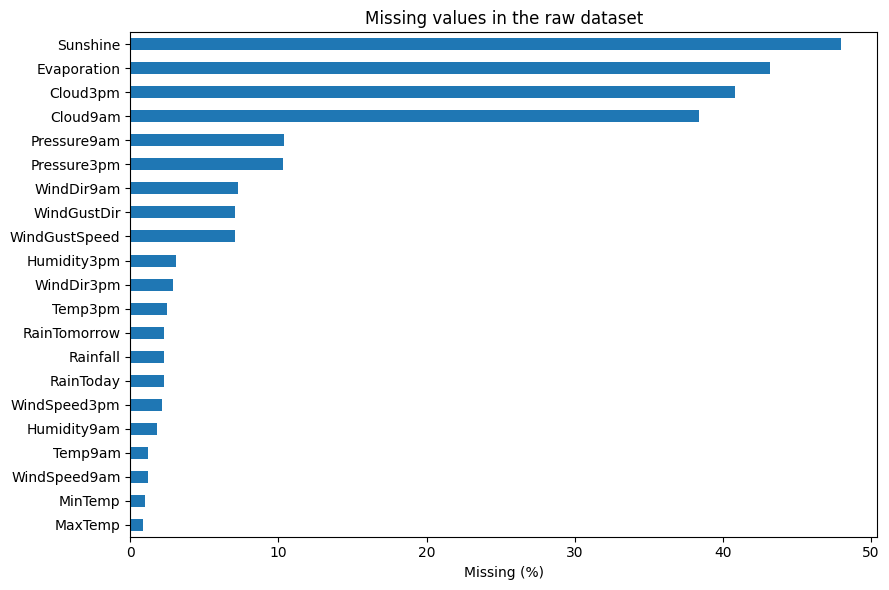

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
missing_report.loc[missing_report.missing_pct > 0, "missing_pct"].sort_values().plot.barh(ax=ax)
ax.set(title="Missing values in the raw dataset", xlabel="Missing (%)", ylabel="")
fig.tight_layout()
plt.show()

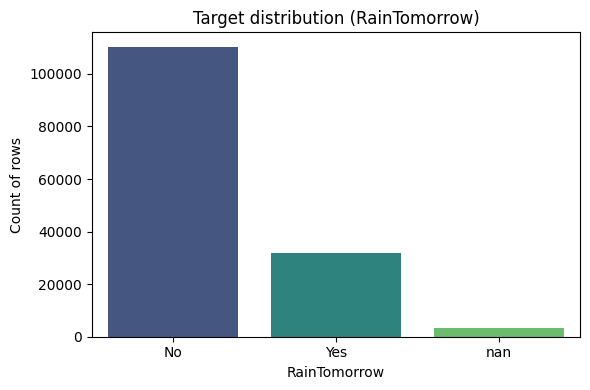

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))

target_counts = raw["RainTomorrow"].value_counts(dropna=False)

x_values = target_counts.index.astype(str)
sns.barplot(x=x_values, y=target_counts.values, ax=ax, palette="viridis", hue=x_values, legend=False)

ax.set(title="Target distribution (RainTomorrow)", xlabel="RainTomorrow", ylabel="Count of rows")
fig.tight_layout()
plt.show()

## 3. Check invalid and suspicious values

Check ranges and categories once before deciding what needs cleaning. Large but plausible weather measurements are retained.

In [6]:
checks = {
    "MinTemp > MaxTemp": int((raw.MinTemp > raw.MaxTemp).sum()),
    "Cloud9am outside [0, 8]": int((raw.Cloud9am.notna() & ~raw.Cloud9am.between(0, 8)).sum()),
    "Cloud3pm outside [0, 8]": int((raw.Cloud3pm.notna() & ~raw.Cloud3pm.between(0, 8)).sum()),
    "Humidity9am outside [0, 100]": int((raw.Humidity9am.notna() & ~raw.Humidity9am.between(0, 100)).sum()),
    "Humidity3pm outside [0, 100]": int((raw.Humidity3pm.notna() & ~raw.Humidity3pm.between(0, 100)).sum()),
    "Negative Rainfall / Evaporation": int(((raw[["Rainfall", "Evaporation"]] < 0).sum()).sum()),
    "Sunshine outside [0, 24] hours": int((raw.Sunshine.notna() & ~raw.Sunshine.between(0, 24)).sum()),
    "Negative wind speed": int(((raw[["WindGustSpeed", "WindSpeed9am", "WindSpeed3pm"]] < 0).sum()).sum()),
    "Non-positive atmospheric pressure": int(((raw[["Pressure9am", "Pressure3pm"]] <= 0).sum()).sum()),
}

display(pd.Series(checks, name="rows / cells").to_frame())
display(raw[NUMERIC_COLUMNS].agg(["min", "median", "max"]).T)

,rows / cells
MinTemp > MaxTemp,0
"Cloud9am outside [0, 8]",2
"Cloud3pm outside [0, 8]",1
"Humidity9am outside [0, 100]",0
"Humidity3pm outside [0, 100]",0
Negative Rainfall / Evaporation,0
"Sunshine outside [0, 24] hours",0
Negative wind speed,0
Non-positive atmospheric pressure,0


,min,median,max
MinTemp,-8.5,12.0,33.9
MaxTemp,-4.8,22.6,48.1
Rainfall,0.0,0.0,371.0
Evaporation,0.0,4.8,145.0
Sunshine,0.0,8.4,14.5
WindGustSpeed,6.0,39.0,135.0
WindSpeed9am,0.0,13.0,130.0
WindSpeed3pm,0.0,19.0,87.0
Humidity9am,0.0,70.0,100.0
Humidity3pm,0.0,52.0,100.0


In [7]:
WIND_DIRECTIONS = {
    "N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE",
    "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"
}

for col in ["WindGustDir", "WindDir9am", "WindDir3pm", "RainToday", "RainTomorrow"]:
    allowed = {"Yes", "No"} if col.startswith("Rain") else WIND_DIRECTIONS
    print(f"Unexpected categories in {col}:", sorted(set(raw[col].dropna()) - allowed))

valid = raw["Rainfall"].notna() & raw["RainToday"].notna()
expected = np.where(raw.loc[valid, "Rainfall"].gt(1), "Yes", "No")
print("RainToday / Rainfall inconsistencies:", (expected != raw.loc[valid, "RainToday"]).sum())

Unexpected categories in WindGustDir: []
Unexpected categories in WindDir9am: []
Unexpected categories in WindDir3pm: []
Unexpected categories in RainToday: []
Unexpected categories in RainTomorrow: []
RainToday / Rainfall inconsistencies: 0


## 4. Data cleaning

- The audit finds three cloud values of 9 outside the assumed 0–8 scale. Treat these as missing, not as clear sky. 
- Other range checks and category checks find no problems, and there are no duplicate records.
- Drop rows without `RainTomorrow` (the target cannot be imputed), parse dates, and encode No/Yes as 0/1. Predictor missing values stay missing until after the split.

In [8]:
df = raw.dropna(subset=["RainTomorrow"]).copy()
df["Date"] = pd.to_datetime(df["Date"], format="%Y-%m-%d")

for col in ["Cloud9am", "Cloud3pm"]:
    invalid = df[col].notna() & ~df[col].between(0, 8)
    print(f"{col}: {invalid.sum()} values replaced with NaN")
    df.loc[invalid, col] = np.nan

df["RainTomorrow"] = df["RainTomorrow"].map({"No": 0, "Yes": 1}).astype("int8")
df["RainToday"] = df["RainToday"].map({"No": 0, "Yes": 1}).astype("Int8")
df = df.sort_values(["Date", "Location"]).reset_index(drop=True)
print(f"Removed {len(raw) - len(df):,} rows with missing target; kept {len(df):,} rows")

Cloud9am: 2 values replaced with NaN
Cloud3pm: 1 values replaced with NaN
Removed 3,267 rows with missing target; kept 142,193 rows


Cloud3pm: 1 values replaced with NaN
Removed 3,267 rows with missing target; kept 142,193 rows


## 5. chronological train / validation / test split

In [9]:
train_df = df.loc[df["Date"].le("2014-12-30")].copy()
val_df = df.loc[df["Date"].between("2015-01-01", "2015-12-30")].copy()
test_df = df.loc[df["Date"].ge("2016-01-01")].copy()
gap_df = df.loc[df["Date"].isin(pd.to_datetime(["2014-12-31", "2015-12-31"]))]
splits = {"train": train_df, "val": val_df, "test": test_df}

assert df[["Date", "Location"]].notna().all().all()
assert not df.duplicated(["Date", "Location"]).any()
assert all(len(part) > 0 for part in splits.values())
assert train_df["Date"].max() + pd.Timedelta(days=1) < val_df["Date"].min()
assert val_df["Date"].max() + pd.Timedelta(days=1) < test_df["Date"].min()
assert sum(len(part) for part in splits.values()) + len(gap_df) == len(df)

In [10]:
summary = pd.DataFrame([
    {"split": name, "rows": len(part),
     "share_pct": round(100 * len(part) / len(df), 2),
     "date_start": part["Date"].min().date(), "date_end": part["Date"].max().date(),
     "rain_pct": round(100 * part["RainTomorrow"].mean(), 2),
     "locations": part["Location"].nunique()}
    for name, part in splits.items()
])

display(summary)
print(f"Excluded at split boundaries: {len(gap_df)} rows")
for name in ["val", "test"]:
    print(f"Stations unseen in train ({name}):", sorted(set(splits[name]["Location"]) - set(train_df["Location"])))

,split,rows,share_pct,date_start,date_end,rain_pct,locations
0,train,98940,69.58,2007-11-01,2014-12-30,22.52,49
1,val,17184,12.08,2015-01-01,2015-12-30,21.22,49
2,test,25974,18.27,2016-01-01,2017-06-25,22.89,49


Excluded at split boundaries: 95 rows
Stations unseen in train (val): []
Stations unseen in train (test): []


## 6. Missing values in train

Use the training period to inspect missingness and choose preprocessing. Median imputation is a simple starting point, but cannot recover station-specific or seasonal conditions where measurements are absent.

In [11]:
display((100 * train_df.isna().mean()).sort_values(ascending=False).round(1).to_frame("missing_pct"))

missing_by_location = train_df.groupby("Location")[["Sunshine", "Evaporation", "Cloud3pm"]].agg(lambda column: round(100 * column.isna().mean(), 1))
display(missing_by_location.sort_values("Sunshine", ascending=False).head(10))

,missing_pct
Sunshine,41.1
Evaporation,37.5
Cloud3pm,37.1
Cloud9am,36.1
Pressure9am,9.4
Pressure3pm,9.4
WindDir9am,7.4
WindGustDir,7.0
WindGustSpeed,7.0
WindDir3pm,2.1


,Sunshine,Evaporation,Cloud3pm
Location,,,
Albury,100.0,100.0,55.6
GoldCoast,100.0,100.0,100.0
BadgerysCreek,100.0,100.0,100.0
Bendigo,100.0,44.4,18.0
Ballarat,100.0,100.0,36.9
Katherine,100.0,4.5,3.6
Wollongong,100.0,100.0,57.1
Walpole,100.0,100.0,100.0
Uluru,100.0,100.0,91.0


## 7. Train-only imputation and encoding

- Numeric measurements: train medians, which are less sensitive to extreme values than means.
- `RainToday`: fill with 0 and add a missingness indicator to distinguish missing from No.
- Station and wind directions: fill with `Missing`, then one-hot encode using categories learned on train. Unseen categories produce zeros for that feature's dummy columns.

Apply these same rules to validation and test.

In [12]:
CATEGORICAL_FEATURES = ["Location", "WindGustDir", "WindDir9am", "WindDir3pm"]
train_medians = train_df[NUMERIC_COLUMNS].median()
assert train_medians.notna().all(), "A numeric feature has no observed training values"
display(train_medians.rename("train_median").to_frame())

,train_median
MinTemp,11.8
MaxTemp,22.4
Rainfall,0.0
Evaporation,4.6
Sunshine,8.4
WindGustSpeed,39.0
WindSpeed9am,13.0
WindSpeed3pm,19.0
Humidity9am,70.0
Humidity3pm,52.0


In [13]:
def impute_using_train(part):
    result = part.copy()
    result[NUMERIC_COLUMNS] = result[NUMERIC_COLUMNS].fillna(train_medians)
    result[CATEGORICAL_FEATURES] = result[CATEGORICAL_FEATURES].fillna("Missing")
    result["RainToday_missing"] = result["RainToday"].isna().astype("int8")
    result["RainToday"] = result["RainToday"].fillna(0).astype("int8")
    return result

imputed = {name: impute_using_train(part) for name, part in splits.items()}

In [14]:
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.uint8)
encoder.fit(imputed["train"][CATEGORICAL_FEATURES])
encoded_names = encoder.get_feature_names_out(CATEGORICAL_FEATURES)

def encode_using_train(part):
    one_hot = pd.DataFrame(encoder.transform(part[CATEGORICAL_FEATURES]),columns=encoded_names, index=part.index,)
    return pd.concat([part.drop(columns=CATEGORICAL_FEATURES[1:]), one_hot], axis=1)

ready = {name: encode_using_train(part) for name, part in imputed.items()}

In [15]:
feature_columns = ready["train"].columns.drop(["Date", "Location", "RainTomorrow"])

for name, part in ready.items():
    assert part.columns.equals(ready["train"].columns)
    assert not part.isna().any().any()
    assert part[["Date", "Location", "RainTomorrow"]].equals(splits[name][["Date", "Location", "RainTomorrow"]])
    assert all(pd.api.types.is_numeric_dtype(part[col]) for col in feature_columns)
    print(f"{name}: {len(part):,} rows, {len(feature_columns)} numeric features, no missing values")

train: 98,940 rows, 118 numeric features, no missing values
val: 17,184 rows, 118 numeric features, no missing values
test: 25,974 rows, 118 numeric features, no missing values


## 8. Export

`weatherAUS_clean.csv` preserves predictor missing values. The train/val/test CSVs contain imputed, encoded features and the same metadata and target.

In [16]:
df.to_csv(DATA_DIR / "weatherAUS_clean.csv", index=False, date_format="%Y-%m-%d")
for name, part in ready.items():
    path = DATA_DIR / f"weatherAUS_{name}.csv"
    part.to_csv(path, index=False, date_format="%Y-%m-%d")
    print(f"Saved {path}")

Saved data\weatherAUS_train.csv
Saved data\weatherAUS_val.csv
Saved data\weatherAUS_test.csv


Saved data\weatherAUS_val.csv


Saved data\weatherAUS_test.csv
